# Neural Bag of Words (NBoW) in PyTorch
Fully self-contained: **the dataset is written inside the code**, with no downloads and no `datasets` import. Vocabulary is capped at **100 words** (98 + `<unk>` + `<pad>`).

## 1. Importing Modules

In [1]:
import collections
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 2. The Dataset (inside the code)
40 positive reviews (label 1) and 40 negative reviews (label 0).

In [2]:
positive_reviews = [
    "this movie was great and i loved every minute",
    "an amazing story with wonderful acting",
    "the film was fantastic and the music was lovely",
    "i really enjoyed the plot and the cast was excellent",
    "a brilliant movie that made me smile",
    "wonderful direction and a perfect ending",
    "the acting was superb and the story was moving",
    "what a delightful and charming film",
    "i loved the script and the characters were great",
    "an excellent film that i would watch again",
    "the music was beautiful and the ending was perfect",
    "a fun movie with a great cast and a clever plot",
    "truly amazing direction and a wonderful story",
    "the film was a joy and i enjoyed it a lot",
    "great acting and a lovely story made this movie special",
    "i found the movie very funny and the cast was brilliant",
    "a stunning film with an excellent script",
    "the story was clever and the ending was wonderful",
    "one of the best movies i have seen this year",
    "a heartwarming story with fantastic acting",
    "the plot was exciting and the music was superb",
    "i would recommend this film to everyone because it was great",
    "a perfect movie with lovely music and a brilliant cast",
    "very enjoyable and the story was amazing",
    "the direction was excellent and the film felt fresh",
    "i loved this movie and the ending made me happy",
    "a wonderful film with charming characters",
    "the acting was great and the plot was clever",
    "an amazing movie that i really loved",
    "the film was beautiful and the story was moving",
    "a delightful script and a fantastic cast",
    "i enjoyed every scene and the music was lovely",
    "the best acting and a perfect story",
    "what a brilliant and fun movie",
    "the story was great and the ending was superb",
    "a lovely film that i enjoyed a lot",
    "excellent acting and a wonderful plot",
    "this film was a delight from start to end",
    "the cast was amazing and the script was clever",
    "a moving story with a perfect ending",
]

negative_reviews = [
    "this movie was terrible and i hated every minute",
    "a boring story with awful acting",
    "the film was dull and the music was bad",
    "i really disliked the plot and the cast was weak",
    "a horrible movie that made me angry",
    "poor direction and a disappointing ending",
    "the acting was bad and the story was boring",
    "what a messy and annoying film",
    "i hated the script and the characters were dull",
    "a terrible film that i would never watch again",
    "the music was awful and the ending was disappointing",
    "a slow movie with a weak cast and a silly plot",
    "truly terrible direction and a boring story",
    "the film was a waste and i disliked it a lot",
    "bad acting and a dull story made this movie painful",
    "i found the movie very boring and the cast was poor",
    "an ugly film with a terrible script",
    "the story was silly and the ending was awful",
    "one of the worst movies i have seen this year",
    "a tedious story with weak acting",
    "the plot was slow and the music was bad",
    "i would not recommend this film to anyone because it was awful",
    "a horrible movie with dull music and a poor cast",
    "very boring and the story was terrible",
    "the direction was poor and the film felt stale",
    "i hated this movie and the ending made me sad",
    "a dreadful film with annoying characters",
    "the acting was bad and the plot was silly",
    "an awful movie that i really hated",
    "the film was ugly and the story was boring",
    "a weak script and a terrible cast",
    "i disliked every scene and the music was dull",
    "the worst acting and a bad story",
    "what a boring and messy movie",
    "the story was bad and the ending was dreadful",
    "a tedious film that i disliked a lot",
    "poor acting and an awful plot",
    "this film was a pain from start to end",
    "the cast was weak and the script was silly",
    "a forgettable story with a disappointing ending",
]

data = [(t, 1) for t in positive_reviews] + [(t, 0) for t in negative_reviews]
random.shuffle(data)
print(len(data), "examples")
data[:3]

80 examples


[('a terrible film that i would never watch again', 0),
 ('very boring and the story was terrible', 0),
 ('very enjoyable and the story was amazing', 1)]

## 3. Creating Data Splits
70% train, 15% validation, 15% test.

In [3]:
n = len(data)
train_pairs = data[: int(0.7 * n)]
valid_pairs = data[int(0.7 * n): int(0.85 * n)]
test_pairs  = data[int(0.85 * n):]
len(train_pairs), len(valid_pairs), len(test_pairs)

(56, 12, 12)

## 4. Tokenizing

In [4]:
def tokenize(text):
    return text.lower().split()

train_data = [(tokenize(t), y) for t, y in train_pairs]
valid_data = [(tokenize(t), y) for t, y in valid_pairs]
test_data  = [(tokenize(t), y) for t, y in test_pairs]
train_data[0]

(['a', 'terrible', 'film', 'that', 'i', 'would', 'never', 'watch', 'again'], 0)

## 5. Creating the Vocabulary (100 words)
Built from the training set only: the 98 most common words + `<unk>` + `<pad>`. Any other word maps to `<unk>`.

In [5]:
MAX_VOCAB = 100
specials = ["<unk>", "<pad>"]

counter = collections.Counter(tok for toks, _ in train_data for tok in toks)
print("Unique words in train:", len(counter))
itos = specials + [w for w, _ in counter.most_common(MAX_VOCAB - len(specials))]
stoi = {w: i for i, w in enumerate(itos)}
unk_idx, pad_idx = stoi["<unk>"], stoi["<pad>"]
print("Vocab size:", len(itos))
print(itos[:20])

Unique words in train: 99
Vocab size: 100
['<unk>', '<pad>', 'the', 'and', 'was', 'a', 'i', 'film', 'story', 'movie', 'with', 'acting', 'ending', 'cast', 'this', 'music', 'script', 'plot', 'terrible', 'bad']


## 6. Numericalizing

In [6]:
def numericalize(tokens):
    return torch.tensor([stoi.get(t, unk_idx) for t in tokens], dtype=torch.long)

def encode(split):
    return [(numericalize(toks), torch.tensor(y, dtype=torch.float)) for toks, y in split]

train_enc, valid_enc, test_enc = encode(train_data), encode(valid_data), encode(test_data)
train_enc[0]

(tensor([ 5, 18,  7, 29,  6, 23, 74, 45, 46]), tensor(0.))

## 7. Creating the Data Loaders
Sentences differ in length, so each batch is padded with `<pad>`.

In [7]:
def collate_fn(batch):
    ids = pad_sequence([x for x, _ in batch], batch_first=True, padding_value=pad_idx)
    labels = torch.stack([y for _, y in batch])
    return {"ids": ids, "label": labels}

batch_size = 8
train_loader = DataLoader(train_enc, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
valid_loader = DataLoader(valid_enc, batch_size=batch_size, collate_fn=collate_fn)
test_loader  = DataLoader(test_enc,  batch_size=batch_size, collate_fn=collate_fn)

## 8. Building the NBoW Model
Embed each token, **average** the embeddings (ignoring padding), then a linear layer outputs one logit.

In [8]:
class NBoW(nn.Module):
    def __init__(self, vocab_size, embedding_dim, pad_index):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_index)
        self.fc = nn.Linear(embedding_dim, 1)
        self.pad_index = pad_index

    def forward(self, ids):
        emb = self.embedding(ids)                                # [B, T, D]
        mask = (ids != self.pad_index).unsqueeze(-1)             # [B, T, 1]
        pooled = (emb * mask).sum(1) / mask.sum(1).clamp(min=1)  # mean of real tokens
        return self.fc(pooled).squeeze(-1)                       # [B]

model = NBoW(len(itos), embedding_dim=16, pad_index=pad_idx).to(device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 1617


## 9. Training and Evaluation

In [9]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-2)

def accuracy(logits, y):
    return ((torch.sigmoid(logits) > 0.5).float() == y).float().mean()

def train_epoch(loader):
    model.train(); losses, accs = [], []
    for b in loader:
        ids, y = b["ids"].to(device), b["label"].to(device)
        optimizer.zero_grad()
        out = model(ids)
        loss = criterion(out, y)
        loss.backward(); optimizer.step()
        losses.append(loss.item()); accs.append(accuracy(out, y).item())
    return np.mean(losses), np.mean(accs)

@torch.no_grad()
def evaluate(loader):
    model.eval(); losses, accs = [], []
    for b in loader:
        ids, y = b["ids"].to(device), b["label"].to(device)
        out = model(ids)
        losses.append(criterion(out, y).item()); accs.append(accuracy(out, y).item())
    return np.mean(losses), np.mean(accs)

history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}
for epoch in range(20):
    tl, ta = train_epoch(train_loader)
    vl, va = evaluate(valid_loader)
    for k, v in zip(history, (tl, vl, ta, va)): history[k].append(v)
    print(f"Epoch {epoch+1:02d} | train loss {tl:.3f} acc {ta:.3f} | valid loss {vl:.3f} acc {va:.3f}")

test_loss, test_acc = evaluate(test_loader)
print(f"Test loss {test_loss:.3f} | Test acc {test_acc:.3f}")

Epoch 01 | train loss 0.703 acc 0.482 | valid loss 0.697 acc 0.562
Epoch 02 | train loss 0.682 acc 0.571 | valid loss 0.685 acc 0.625
Epoch 03 | train loss 0.668 acc 0.589 | valid loss 0.671 acc 0.625
Epoch 04 | train loss 0.650 acc 0.679 | valid loss 0.660 acc 0.625
Epoch 05 | train loss 0.630 acc 0.679 | valid loss 0.648 acc 0.562
Epoch 06 | train loss 0.606 acc 0.750 | valid loss 0.631 acc 0.625
Epoch 07 | train loss 0.582 acc 0.821 | valid loss 0.609 acc 0.750
Epoch 08 | train loss 0.549 acc 0.911 | valid loss 0.588 acc 0.750
Epoch 09 | train loss 0.516 acc 0.946 | valid loss 0.565 acc 0.812
Epoch 10 | train loss 0.474 acc 0.946 | valid loss 0.537 acc 0.812
Epoch 11 | train loss 0.432 acc 0.946 | valid loss 0.506 acc 0.812
Epoch 12 | train loss 0.387 acc 0.946 | valid loss 0.474 acc 0.812
Epoch 13 | train loss 0.344 acc 0.982 | valid loss 0.447 acc 0.938
Epoch 14 | train loss 0.300 acc 0.982 | valid loss 0.421 acc 0.938
Epoch 15 | train loss 0.259 acc 0.982 | valid loss 0.396 acc 0

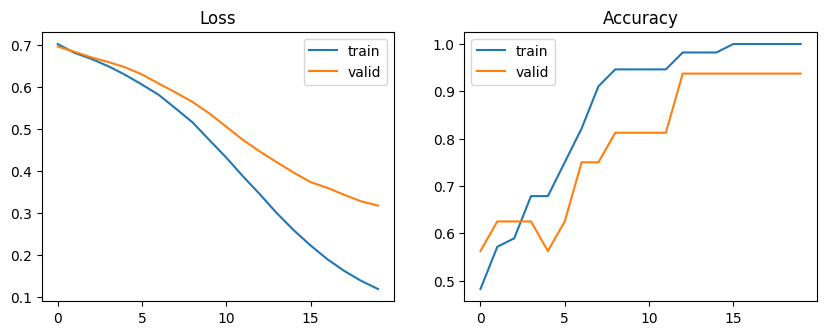

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["valid_loss"], label="valid"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["valid_acc"], label="valid"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

## 10. Predicting on New Text

In [11]:
@torch.no_grad()
def predict(text):
    model.eval()
    ids = numericalize(tokenize(text)).unsqueeze(0).to(device)
    p = torch.sigmoid(model(ids)).item()
    return ("positive" if p > 0.5 else "negative"), round(p, 3)

for s in ["the movie was really great", "the story was boring and bad", "an excellent film with lovely music"]:
    print(s, "->", predict(s))

the movie was really great -> ('positive', 0.795)
the story was boring and bad -> ('negative', 0.023)
an excellent film with lovely music -> ('positive', 0.984)
